<a href="https://colab.research.google.com/github/ShiaMicaNaomiOnix/Crime-/blob/main/%EC%82%AC%EC%9D%B4%EB%B2%84%EB%B2%94%EC%A3%84_%EC%9B%94%EB%B3%84_%EB%8D%B0%EC%9D%B4%ED%84%B0_%ED%91%9C%EB%A1%9C_%EC%97%AC%EB%9F%AC_%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D_%EB%AA%A8%EB%8D%B8_%EB%A7%8C%EB%93%A4%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#월별 데이터 표로 다양한 알고리즘을 만들어서 만든 시계열 예측 모델들

## 0. Python 시계열 예측 모델
- 첫번째 코드의 시계열 예측 모델은 prophet으로 만들어진 모델
  - prophet 모델:
  - 활용이유1: 데이터에 내재된 연간 주기성(Yearly Seasonality)과 전체적인 추세(Trend)를 자동으로 감지한다. 또한 연도별 특정 월에 반복되는 범죄 발생 패턴을 포착하기에 적합하다.
  - 데이터 포멧팅을 진행할 때 prophet은 입력값으로 날짜 컬럼(ds)과 타겟 컬럼(y)을 요구하기에 기존의 연도와 월_숫자를 결합하며 매월 1월 기준(YYYY-MM-01)의 데이터로 변환 후 학습시킴
  - 이 것을 진행하고 파생 변수를 계산할 때 예측된 발생건수와 검거건수를 기반으로 2024년의 예측 검거율을 추가로 계산해 직관성을 올림



=== 2024년 월별 시계열 예측 결과 ===
 월  예측 발생건수  예측 검거건수  예측 검거율(%)
 1 21852.62 11512.48      52.68
 2 18588.75 10080.31      54.23
 3 22844.35 12948.34      56.68
 4 22428.93 14081.28      62.78
 5 20317.35 11740.34      57.78
 6 24620.47 14340.73      58.25
 7 21982.62 12563.40      57.15
 8 21720.43 12389.17      57.04
 9 24005.25 14938.43      62.23
10 23115.48 14095.39      60.98
11 22064.95 11560.02      52.39
12 23497.65 11844.44      50.41


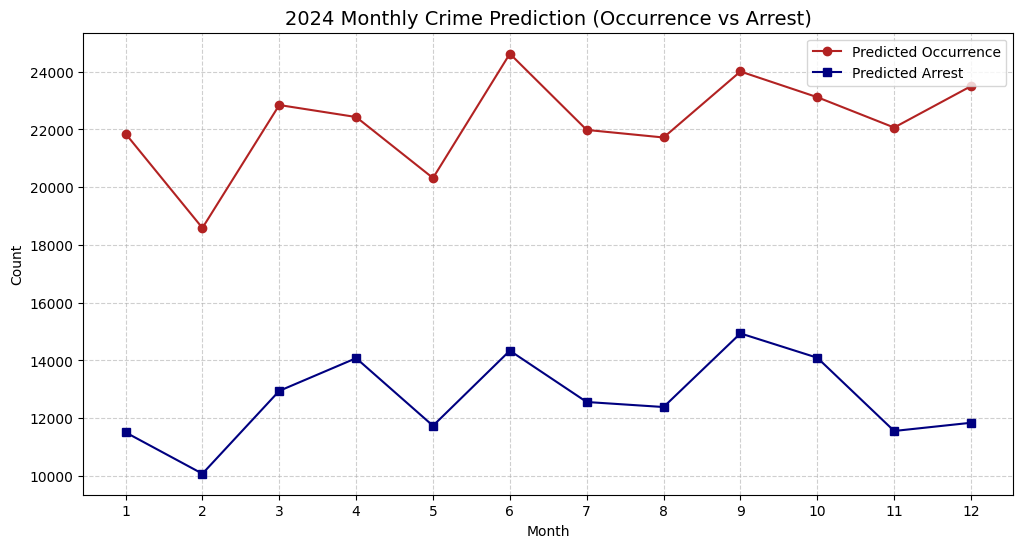

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet

# 1. 데이터 불러오기 및 전처리
# 파일 경로는 환경에 맞게 수정해주세요.
df = pd.read_csv('월별 추이.csv')

# Prophet 모델 형식에 맞게 데이터프레임 구성 (ds: 날짜, y: 예측할 값)
# 연도와 월을 합쳐서 YYYY-MM-DD 형식의 datetime 객체로 변환합니다.
df['ds'] = pd.to_datetime(df['연도'].astype(str) + '-' + df['월_숫자'].astype(str) + '-01')

# 2. '발생건수' 예측 모델 학습 및 예측
df_occur = df[['ds', '합계 발생건수개']].rename(columns={'합계 발생건수개': 'y'})

model_occur = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
model_occur.fit(df_occur)

# 2024년 1월부터 12월까지의 미래 데이터프레임 생성 (월별 주기: freq='MS')
future_occur = model_occur.make_future_dataframe(periods=12, freq='MS')
forecast_occur = model_occur.predict(future_occur)

# 3. '검거건수' 예측 모델 학습 및 예측
df_arrest = df[['ds', '합계 검거건수개']].rename(columns={'합계 검거건수개': 'y'})

model_arrest = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
model_arrest.fit(df_arrest)

future_arrest = model_arrest.make_future_dataframe(periods=12, freq='MS')
forecast_arrest = model_arrest.predict(future_arrest)

# 4. 2024년 예측 결과만 필터링 및 병합
pred_2024_occur = forecast_occur[forecast_occur['ds'] >= '2024-01-01'][['ds', 'yhat']].rename(columns={'yhat': '예측 발생건수'})
pred_2024_arrest = forecast_arrest[forecast_arrest['ds'] >= '2024-01-01'][['ds', 'yhat']].rename(columns={'yhat': '예측 검거건수'})

result_2024 = pd.merge(pred_2024_occur, pred_2024_arrest, on='ds')
result_2024['예측 검거율(%)'] = (result_2024['예측 검거건수'] / result_2024['예측 발생건수']) * 100
result_2024['월'] = result_2024['ds'].dt.month

# 소수점 둘째 자리까지 깔끔하게 정리
result_2024 = result_2024[['월', '예측 발생건수', '예측 검거건수', '예측 검거율(%)']].round(2)

print("=== 2024년 월별 시계열 예측 결과 ===")
print(result_2024.to_string(index=False))

# 5. 결과 시각화
plt.figure(figsize=(12, 6))
plt.plot(result_2024['월'], result_2024['예측 발생건수'], marker='o', label='Predicted Occurrence', color='firebrick')
plt.plot(result_2024['월'], result_2024['예측 검거건수'], marker='s', label='Predicted Arrest', color='navy')
plt.title('2024 Monthly Crime Prediction (Occurrence vs Arrest)', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Count')
plt.xticks(result_2024['월'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

- 두번째 코드의 시계열 예측 모델은 트리 기반 모델(LightGBM, Random Forest), 서포트 벡터 회귀(SVR-Support Vector Regression), K-최근접 이웃 회귀(KNN Regressor), 릿지/라쏘 회귀(Ridge/Lasso Regression) 입니다.
  - 트리 기반 모델(LightGBM, Random Forest)
  - 서포트 벡터 회귀(SVR-Support Vector Regression)
    - 분류 알고리즘으로 유명함. 데이터가 적을 떄 매우 강력함. 데이터의 전반적인 흐름을 유연하고 매끄러운 곡선 형태로 예측하는데 특화되어 있음.
    - 마진(Margin)이라는 개념을 둬 특정 오차 범위 내의 데이터는 무시하고 경계선에 있는 중요한 데이터(서포트 벡터)만으로 가지고 예측 벽을 세우기에 과적합(Overfitting)이 덜 일어남
  - K-최근접 이웃 회귀(KNN Regressor)
    - 가장 직관적인 머신러닝 알고리즘 중 하나. 미래의 특정 시점을 예측할 때, 과거 데이터중 가장 특성이 유사한 K개의 데이터를 찾아 그 값들의 평균으로 예측하는 방식임
  - 릿지/라쏘 회귀(Ridge/Lasso Regression): 12계월 전(작년 동월)의 데이터가 중요한지, 바로 전달 데이터가 중요한지 모델이 스스로 판단해 선형적인 예측을 만듦.

In [ ]:
import pandas as pd
import numpy as np
#from statsmodels.tsa.api import HoltWintersResults
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ExpSineSquared
from sklearn.preprocessing import MinMaxScaler
from lightgbm import LGBMRegressor
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# 1. 데이터 로드 및 전처리
df = pd.read_csv('월별 추이.csv')
df['Date'] = pd.to_datetime(df['연도'].astype(str) + '-' + df['월_숫자'].astype(str) + '-01')
df = df.sort_values('Date').reset_index(drop=True)

# 예측 결과를 담을 딕셔너리 (2024년 1월 ~ 12월)
target_months = range(1, 13)
results = {'월': list(target_months)}

# =========================================================================
# [1계열] Holt-Winters Exponential Smoothing (전통 지수평활 계열)
# =========================================================================
# 추세와 12개월 주기의 계절성을 점진적으로 가중치를 주어 반영하는 모델
model_hw = ExponentialSmoothing(df['합계 발생건수개'], trend='add', seasonal='add', seasonal_periods=12)
fit_hw = model_hw.fit()
results['1_HoltWinters'] = fit_hw.forecast(12).values

# =========================================================================
# [2계열] SARIMAX (선형 통계학 확률 모델 계열)
# =========================================================================
# 데이터의 자체 작용(AR), 오차 이동평균(MA), 계절성 주기를 확률적으로 계산
model_sarima = SARIMAX(df['합계 발생건수개'], order=(1,1,1), seasonal_order=(1,1,1,12))
fit_sarima = model_sarima.fit(disp=False)
results['2_SARIMAX'] = fit_sarima.forecast(12).values

# =========================================================================
# [3계열] Random Forest Regressor (전통 배깅 머신러닝 계열)
# =========================================================================
# 데이터가 적을 때 오버피팅을 억제하며 의사결정나무의 평균으로 예측
df['이전_발생'] = df['합계 발생건수개'].shift(1)
df_ml = df.dropna().copy()

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(df_ml[['월_숫자', '이전_발생']], df_ml['합계 발생건수개'])

rf_preds = []
last_val = df['합계 발생건수개'].iloc[-1]
for m in target_months:
    pred = rf.predict([[m, last_val]])[0]
    rf_preds.append(pred)
    last_val = pred
results['3_RandomForest'] = rf_preds

# =========================================================================
# [4계열] LightGBM Regressor (부스팅 머신러닝 계열)
# =========================================================================
# 잔차(오차)를 대치해가며 순차적으로 나무를 앙상블하는 기법 (XGBoost 사촌)
lgb = LGBMRegressor(n_estimators=30, learning_rate=0.05, random_state=42, verbose=-1)
lgb.fit(df_ml[['월_숫자', '이전_발생']], df_ml['합계 발생건수개'])

lgb_preds = []
last_val = df['합계 발생건수개'].iloc[-1]
for m in target_months:
    pred = lgb.predict([[m, last_val]])[0]
    lgb_preds.append(pred)
    last_val = pred
results['4_LightGBM'] = lgb_preds

# =========================================================================
# [5계열] Gaussian Process Regression (커널 기반 확률적 머신러닝 계열)
# =========================================================================
# 무한한 함수들의 분포를 가정하고, 12개월의 주기성 커널을 주입해 푸는 방식
X_gpr = np.arange(len(df)).reshape(-1, 1)
y_gpr = df['합계 발생건수개'].values

kernel = RBF(length_scale=12.0) + ExpSineSquared(length_scale=1.0, periodicity=12.0)
gpr = GaussianProcessRegressor(kernel=kernel, random_state=42)
gpr.fit(X_gpr, y_gpr)

X_future = np.arange(len(df), len(df)+12).reshape(-1, 1)
results['5_GaussianProcess'] = gpr.predict(X_future)

# =========================================================================
# [6계열] Simple RNN (기초 순환신경망 딥러닝 계열)
# =========================================================================
# LSTM의 모태가 되는 가장 기본적인 RNN 구조로 시퀀스를 학습
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df['합계 발생건수개'].values.reshape(-1, 1))

X_rnn, y_rnn = [], []
window_size = 12  # 과거 12개월을 보고 다음 달 예측
for i in range(window_size, len(scaled_data)):
    X_rnn.append(scaled_data[i-window_size:i, 0])
    y_rnn.append(scaled_data[i, 0])
X_rnn, y_rnn = np.array(X_rnn), np.array(y_rnn)
X_rnn = np.reshape(X_rnn, (X_rnn.shape[0], X_rnn.shape[1], 1))

np.random.seed(42)
tf.random.set_seed(42)

model_rnn = Sequential([
    SimpleRNN(8, activation='tanh', input_shape=(window_size, 1)),
    Dense(1)
])
model_rnn.compile(optimizer='adam', loss='mse')
model_rnn.fit(X_rnn, y_rnn, epochs=50, batch_size=4, verbose=0)

rnn_input = scaled_data[-window_size:].reshape(1, window_size, 1)
rnn_preds = []
for _ in target_months:
    pred_scaled = model_rnn.predict(rnn_input, verbose=0)[0, 0]
    rnn_preds.append(pred_scaled)
    rnn_input = np.append(rnn_input[:, 1:, :], [[[pred_scaled]]], axis=1)

results['6_SimpleRNN'] = scaler.inverse_transform(np.array(rnn_preds).reshape(-1, 1)).flatten()

# =========================================================================
# 결과 출력 및 통합
# =========================================================================
df_forecast = pd.DataFrame(results).round(1)
print("\n" + "="*50)
print("       2024년 알고리즘 계열별 예측치 비교")
print("="*50)
print(df_forecast.to_string(index=False))

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warni


       2024년 알고리즘 계열별 예측치 비교
 월  1_HoltWinters  2_SARIMAX  3_RandomForest  4_LightGBM  5_GaussianProcess  6_SimpleRNN
 1        17829.3    19816.8         17347.9     18646.0            16305.2 19087.400391
 2        16215.7    18232.5         16666.8     18284.3            16305.2 18962.699219
 3        19929.9    21595.0         17222.3     18284.3            16305.2 19087.199219
 4        19693.8    20966.5         19334.9     18284.3            16305.2 19016.300781
 5        20048.0    22971.4         21657.5     18284.3            16305.2 19012.099609
 6        21234.3    22240.3         19430.2     18558.5            16305.2 18965.800781
 7        20747.2    21709.5         20862.6     18558.5            16305.2 18976.800781
 8        20925.1    21811.0         19877.8     18989.8            16305.2 18971.400391
 9        20913.1    21746.5         21149.6     19351.5            16305.2 18971.199219
10        22572.0    23417.1         21676.6     19351.5            16305.2 1896

#정확도가 높은 머신러닝 모델

## 1. 전통 통계학 계열: SARIMAX
- 데이터 자체의 과거 겂(AR), 오차(MA), 추세(integration)뿐만 아니라 계절성까지 모두 반영할 수 있어 월별 범죄 데이터 예측에 매우 강력함

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 데이터 로드 및 인덱스 설정
df = pd.read_csv('월별 추이.csv')
df['Date'] = pd.to_datetime(df['연도'].astype(str) + '-' + df['월_숫자'].astype(str) + '-01')
df.set_index('Date', inplace=True)
df = df.sort_index()

# 1. 발생건수 SARIMAX 모델 학습 및 예측 (주기 S=12)
# (p,d,q) 및 (P,D,Q,S) 파라미터는 데이터에 맞게 최적화가 필요합니다.
model_occur = SARIMAX(df['합계 발생건수개'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
results_occur = model_occur.fit(disp=False)
pred_occur = results_occur.forecast(steps=12)

# 2. 검거건수 SARIMAX 모델 학습 및 예측
model_arrest = SARIMAX(df['합계 검거건수개'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
results_arrest = model_arrest.fit(disp=False)
pred_arrest = results_arrest.forecast(steps=12)

# 결과 데이터프레임 구성
months = pd.date_range(start='2024-01-01', periods=12, freq='MS')
result_sarima = pd.DataFrame({
    '월': months.month,
    '예측 발생건수': pred_occur.values,
    '예측 검거건수': pred_arrest.values
}).round(2)

print("=== SARIMAX 2024년 예측 결과 ===")
print(result_sarima.to_string(index=False))

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used

=== SARIMAX 2024년 예측 결과 ===
 월  예측 발생건수  예측 검거건수
 1 19816.83  9168.51
 2 18232.49  8851.18
 3 21594.99 11468.35
 4 20966.46 11324.30
 5 22971.38 12743.99
 6 22240.26 13174.84
 7 21709.50 11329.36
 8 21810.99 12098.80
 9 21746.45 12920.99
10 23417.11 14197.39
11 20596.53 10100.42
12 20831.43  9281.09


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 2. 머신러닝 회귀 계열: XGBoost/LightGBM
- 시계열 문제를 일반적인 지도학습(Supervised Learning) 회귀 문제로 변환하여 푸는 방식
- 날짜 데이터를 파생변수(월, 분기, 이전 달의 발생건수 등)으로 쪼개 트리 기반 모델에 학습시킴
- 데이터의 비선형적인 급증이나 급감을 잡아내는데 유리함

In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor

df = pd.read_csv('월별 추이.csv')

# 지도학습 형태로 변환: '이전 달의 발생건수(Lag_1)'를 피처로 사용
df['이전_발생'] = df['합계 발생건수개'].shift(1)
df['이전_검거'] = df['합계 검거건수개'].shift(1)
df_ml = df.dropna()

# 피처와 타겟 분리
X_occur = df_ml[['월_숫자', '이전_발생']]
y_occur = df_ml['합계 발생건수개']

# 모델 학습
xgb_occur = XGBRegressor(n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42)
xgb_occur.fit(X_occur, y_occur)

# 2024년 1월부터 순차적으로 예측 (재귀적 예측 방식)
last_occur = df['합계 발생건수개'].iloc[-1]
predictions_occur = []

for m in range(1, 13):
    pred = xgb_occur.predict(pd.DataFrame([[m, last_occur]], columns=['월_숫자', '이전_발생']))[0]
    predictions_occur.append(pred)
    last_occur = pred  # 예측값을 다음 달의 피처로 재사용

print("=== XGBoost 2024년 발생건수 예측 ===")
for m, val in enumerate(predictions_occur, 1):
    print(f"{m}월 예측 발생건수: {val:.2f}")

=== XGBoost 2024년 발생건수 예측 ===
1월 예측 발생건수: 17471.29
2월 예측 발생건수: 17421.42
3월 예측 발생건수: 20611.98
4월 예측 발생건수: 20247.21
5월 예측 발생건수: 20336.96
6월 예측 발생건수: 20434.28
7월 예측 발생건수: 20434.28
8월 예측 발생건수: 20531.26
9월 예측 발생건수: 20606.96
10월 예측 발생건수: 21513.99
11월 예측 발생건수: 19668.16
12월 예측 발생건수: 20454.67


##3. 딥러닝 계열: LSTM(Long Short-Term Memory)
- 데이터의 순차적인 흐름과 장단기 기억을 보존하는데 특화된 RNN 계열의 딥러닝 모델
- 이 데이터는 과적함(Overfitting)의 위험이 있어 모델 구조를 가볍게 가져감

In [ ]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

df = pd.read_csv('월별 추이.csv')
data = df['합계 발생건수개'].values.reshape(-1, 1)

# 데이터 정규화 (LSTM은 스케일링이 필수적입니다)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# 시퀀스 데이터 생성 (최근 12개월 데이터를 보고 다음 달을 예측)
X, y = [], []
for i in range(12, len(scaled_data)):
    X.append(scaled_data[i-12:i, 0])
    y.append(scaled_data[i, 0])
X, y = np.array(X), np.array(y)
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

# LSTM 모델 구성
model = Sequential([
    LSTM(16, activation='relu', input_shape=(12, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X, y, epochs=100, batch_size=4, verbose=0)

# 2024년 12개월 예측 진행
current_batch = scaled_data[-12:].reshape(1, 12, 1)
lstm_preds = []

for _ in range(12):
    current_pred = model.predict(current_batch, verbose=0)[0, 0]
    lstm_preds.append(current_pred)
    # 예측값을 포함하여 배치 업데이트
    current_batch = np.append(current_batch[:, 1:, :], [[[current_pred]]], axis=1)

# 역정규화로 실제 건수 복원
actual_preds = scaler.inverse_transform(np.array(lstm_preds).reshape(-1, 1))
print("=== LSTM 2024년 발생건수 예측 ===")
for m, val in enumerate(actual_preds.flatten(), 1):
    print(f"{m}월 예측 발생건수: {val:.2f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


=== LSTM 2024년 발생건수 예측 ===
1월 예측 발생건수: 19156.21
2월 예측 발생건수: 19635.54
3월 예측 발생건수: 20167.73
4월 예측 발생건수: 20146.78
5월 예측 발생건수: 20199.01
6월 예측 발생건수: 19684.77
7월 예측 발생건수: 19764.32
8월 예측 발생건수: 19810.28
9월 예측 발생건수: 19580.17
10월 예측 발생건수: 19413.91
11월 예측 발생건수: 19049.39
12월 예측 발생건수: 19132.68


# 정확도가 떨어지지만 시도해볼 수 있는 머신러닝 모델

## 1. 베이지안 구조적 시계열 모델 (BSTS - Bayesian Structural Time Series)
- 확률적인 최소/최대 범위를 제공하는 모델
- 장점: 데이터의 불확실성을 시각적으로 명확히 보여줌
- Python에서 CausalImpact나 pymc를 활용해 구현함

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

df = pd.read_csv('월별 추이.csv')

# 전통적인 지수평활법(ETS)의 베이지안적 접근을 통해 신뢰구간 계산
model = ETSModel(df['합계 발생건수개'].astype(float), error='add', trend='add', seasonal='add', seasonal_periods=12)
fit = model.fit(disp=False)

# 2024년 12개월 예측 및 상/하한선(95% 신뢰구간) 추출
pred = fit.get_prediction(start=len(df), end=len(df)+11)
pred_summary = pred.summary_frame(alpha=0.05) # 95% 신뢰구간

print("=== 2024년 범위 기반 예측 ===")
result_range = pd.DataFrame({
    '월': range(1, 13),
    '최저 예측치': pred_summary['pi_lower'].values,
    '중앙 예측치': pred_summary['mean'].values,
    '최고 예측치': pred_summary['pi_upper'].values
}).round(0)
print(result_range.to_string(index=False))

=== 2024년 범위 기반 예측 ===
 월  최저 예측치  중앙 예측치  최고 예측치
 1 13104.0 17875.0 22647.0
 2 10907.0 15863.0 20819.0
 3 15069.0 20203.0 25336.0
 4 14836.0 20141.0 25447.0
 5 15831.0 21303.0 26774.0
 6 16022.0 21655.0 27288.0
 7 15385.0 21175.0 26965.0
 8 15637.0 21580.0 27524.0
 9 15388.0 21480.0 27573.0
10 16926.0 23164.0 29402.0
11 12899.0 19279.0 25659.0
12 13300.0 19820.0 26339.0


## 2. 가우시안 프로세스 회귀 (Gaussian Process Regression, GPR)
- 과거 데이터와 가까운 시점은 정확하 맞히고, 과거 데이터와 멀어질수록(미래로 갈수록) 스스로 불확실성(에러 마진)을 넒혀가며 예측함
- 장점: 데이터가 부족할 때 모델이 '모른다'라는 것을 표현할 수 있어 과적합을 막아줌

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ExpSineSquared
import numpy as np

# 인덱스를 기반으로 학습 (1부터 84까지의 월)
X_train = np.arange(len(df)).reshape(-1, 1)
y_train = df['합계 발생건수개'].values

# 커널 설정: 전체적인 추세(RBF) + 12개월 주기성(ExpSineSquared) 결합
kernel = RBF(length_scale=10.0) + ExpSineSquared(length_scale=1.0, periodicity=12.0)
gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, random_state=42)
gpr.fit(X_train, y_train)

# 2024년 (85번째 달부터 96번째 달까지) 예측
X_future = np.arange(len(df), len(df)+12).reshape(-1, 1)
y_pred, sigma = gpr.predict(X_future, return_std=True)

print("=== 가우시안 프로세스 예측 (표준편차 포함) ===")
for m, val, std in zip(range(1, 13), y_pred, sigma):
    print(f"{m}월 예측: {val:.1f} (오차 범위: ±{std:.1f})")

=== 가우시안 프로세스 예측 (표준편차 포함) ===
1월 예측: 18880.0 (오차 범위: ±1.0)
2월 예측: 18796.8 (오차 범위: ±1.0)
3월 예측: 18708.4 (오차 범위: ±1.0)
4월 예측: 18615.1 (오차 범위: ±1.0)
5월 예측: 18516.7 (오차 범위: ±1.0)
6월 예측: 18413.5 (오차 범위: ±1.0)
7월 예측: 18305.5 (오차 범위: ±1.0)
8월 예측: 18192.8 (오차 범위: ±1.0)
9월 예측: 18075.4 (오차 범위: ±1.0)
10월 예측: 17953.6 (오차 범위: ±1.1)
11월 예측: 17827.4 (오차 범위: ±1.1)
12월 예측: 17696.8 (오차 범위: ±1.1)
